# Predicting gene-pair responses beyond additivity
**Pramika Garg · pg2899 · Interim experiments**

This executed notebook reads the saved results produced by the accompanying scripts.
It does not download data or retrain models when run. See `README.md` for complete rerun commands.
The models are explicitly condition-mean GEARS architecture pilots, not a reproduction of the published single-cell training procedure.

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd()
if not (ROOT / 'results').exists():
    ROOT = ROOT / 'interim'
assert (ROOT / 'results').exists()
summary = json.loads((ROOT / 'data/processed/data_summary.json').read_text())
pd.Series({k: summary[k] for k in ['original_cells','retained_cells','genes','original_conditions','retained_conditions','singles','pairs','control_cells','excluded_cells','zero_fraction']}, name='Measured value')

original_cells         84986.0000
retained_cells         84143.0000
genes                  19264.0000
original_conditions      227.0000
retained_conditions      225.0000
singles                  100.0000
pairs                    124.0000
control_cells           7275.0000
excluded_cells           843.0000
zero_fraction              0.8514
Name: Measured value, dtype: float64

## Data and preprocessing
The source AnnData already contains continuous, nonnegative expression with `log1p` metadata.
No second normalization is applied. Conditions containing IER5L are excluded because that target
is missing from the supplied GO dictionary. PCA is descriptive and is never fed into the model.

,count,sum,min,median,max
type,,,,,
control,1,7275,7275,7275.0,7275
pair,124,31848,46,247.5,1005
single,100,45020,95,410.5,1629


Excluded conditions: ['IER5L', 'IER5L+LYL1']
Nonfinite stored values: 0
PCA explained variance: [0.3513 0.2264]


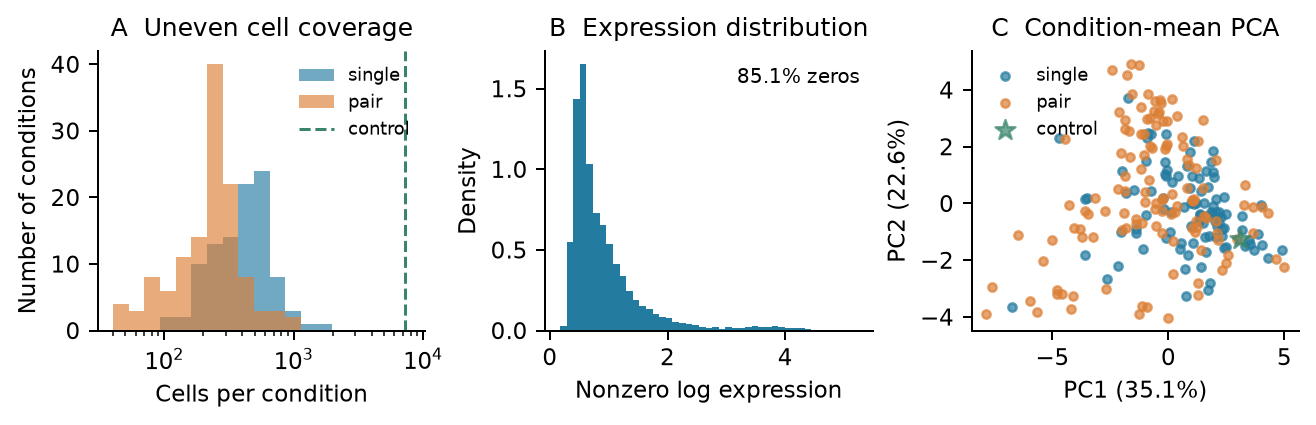

In [2]:
conditions = pd.read_csv(ROOT / 'data/processed/conditions.csv')
display(conditions.groupby('type').n_cells.agg(['count','sum','min','median','max']))
print('Excluded conditions:', summary['excluded_conditions'])
print('Nonfinite stored values:', summary['nonfinite_values'])
print('PCA explained variance:', np.round(summary['pca_variance_ratio'][:2], 4))
display(Image(filename=str(ROOT / 'figures/02_eda.png')))

## Pair partitions and evaluation
All single-gene perturbations are observed during training. Each pair is assigned to exactly
one train/validation/test partition within a split. Repeated test appearances are not independent
samples. Positive paired improvement means `MSE_additive - MSE_model > 0`.

In [3]:
splits = json.loads((ROOT / 'data/processed/splits.json').read_text())
rows = []
for s in splits:
    tr, va, te = map(set, [s['train'], s['validation'], s['test']])
    assert not (tr & va or tr & te or va & te)
    rows.append({'partition_seed':s['seed'], 'train_pairs':sum('+' in c for c in tr), 'validation_pairs':len(va), 'test_pairs':len(te)})
display(pd.DataFrame(rows))
print('Unique tested pairs:', len({c for s in splits for c in s['test']}))

,partition_seed,train_pairs,validation_pairs,test_pairs
0,101,62,31,31
1,202,62,31,31
2,303,62,31,31
3,404,62,31,31
4,505,62,31,31


Unique tested pairs: 98


## Simple baselines across five partitions
The training mean weights perturbation conditions equally and excludes controls.
No-change prediction has zero control-relative shift, so its Pearson correlation is undefined.
The primary result uses MSE, avoiding that undefined correlation.

In [4]:
baseline = pd.read_csv(ROOT / 'results/baseline_summary.csv')
display(baseline)
display(pd.read_csv(ROOT / 'results/baseline_split_metrics.csv'))

,method,unique_test_pairs,mean_mse,mean_paired_improvement,ci_low,ci_high,fraction_pairs_better
0,Additive,98,0.009288,0.000000,0.000000,0.000000,0.000000
1,No change,98,0.036356,-0.027067,-0.031702,-0.022683,0.091837
2,Training mean,98,0.020559,-0.011271,-0.013942,-0.008716,0.142857


,split,method,mean_mse,mean_delta,n_pairs
0,101,Additive,0.010982,0.000000,31
1,101,No change,0.035084,-0.024102,31
2,101,Training mean,0.018693,-0.007711,31
3,202,Additive,0.009588,0.000000,31
4,202,No change,0.034190,-0.024603,31
5,202,Training mean,0.020372,-0.010784,31
6,303,Additive,0.006907,0.000000,31
7,303,No change,0.037243,-0.030336,31
8,303,Training mean,0.021269,-0.014362,31
9,404,Additive,0.009149,0.000000,31


## Model pilots and embedding coverage
Both models use partition 101 and initialization seed 17, with validation-based checkpoint selection.
They use condition means, ordinary MSE, 32 hidden units, all 19,264 genes and a 100-target GO graph.
These departures from the published cell-level protocol prevent treating this as its reproduction.
The GenePT pilot adds fixed NCBI-description features through a learned projection and scale.

In [5]:
runs = [json.loads((ROOT / f'results/{slug}_run.json').read_text()) for slug in ['gears','gears_genept']]
display(pd.DataFrame(runs)[['method','split','seed','epochs_completed','best_epoch','validation_mse','test_mse','hidden','readout_genes','parameters','wall_seconds']])
display(pd.Series(json.loads((ROOT / 'results/embedding_coverage.json').read_text())))
display(pd.read_csv(ROOT / 'results/common_split_comparison.csv'))

,method,split,seed,epochs_completed,best_epoch,validation_mse,test_mse,hidden,readout_genes,parameters,wall_seconds
0,GEARS pilot,101,17,11,6,0.023728,0.023684,32,19264,3155680,89.194903
1,GEARS + GenePT pilot,101,17,14,9,0.025794,0.023933,32,19264,3204929,122.801000


source          Zenodo 10833191, GenePT_gene_embedding_ada_tex...
variant            NCBI gene descriptions, text-embedding-ada-002
dimension                                                    1536
target_genes                                                  100
covered                                                       100
missing                                                        []
dtype: object

,method,n_pairs,mean_mse,mean_difference,ci_low,ci_high
0,Additive,31,0.010982,0.000000,0.000000,0.000000
1,Training mean,31,0.018693,-0.007711,-0.011639,-0.003502
2,No change,31,0.035084,-0.024102,-0.031069,-0.016929
3,GEARS pilot,31,0.023684,-0.012702,-0.017466,-0.007540
4,GEARS + GenePT pilot,31,0.023933,-0.012951,-0.018033,-0.007593


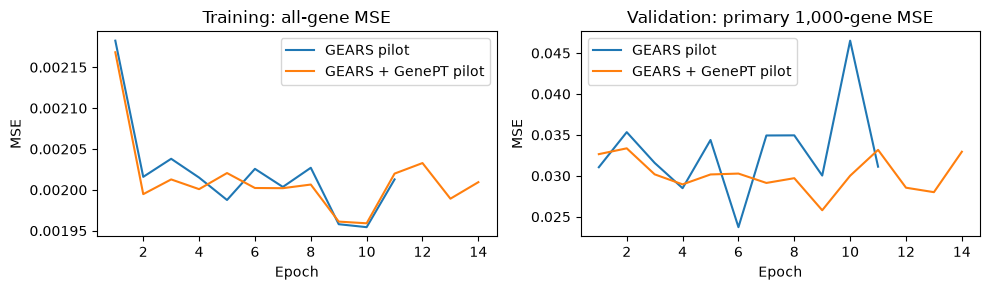

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for slug, label in [('gears','GEARS pilot'), ('gears_genept','GEARS + GenePT pilot')]:
    h = pd.read_csv(ROOT / f'results/{slug}_training_history.csv')
    axes[0].plot(h.epoch, h.training_mse, label=label)
    axes[1].plot(h.epoch, h.validation_mse, label=label)
for ax, title in zip(axes, ['Training: all-gene MSE', 'Validation: primary 1,000-gene MSE']):
    ax.set(xlabel='Epoch', ylabel='MSE', title=title)
    ax.legend()
fig.tight_layout()
plt.show()

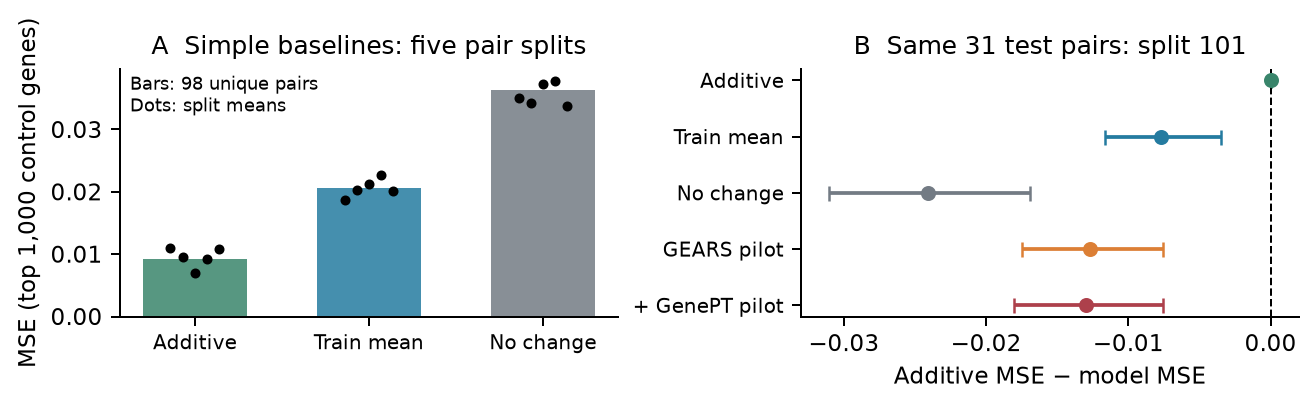

In [7]:
display(Image(filename=str(ROOT / 'figures/03_performance.png')))

## Interaction repeatability
The two residual estimates use independent cell halves within each constituent control,
single and pair condition. They do not share the same noisy control/single means.
This is within-screen repeatability, not independent biological replication.

In [8]:
repeatability = pd.read_csv(ROOT / 'results/residual_repeatability.csv')
display(repeatability.describe())
display(repeatability.nlargest(5, 'residual_rms'))

,residual_rms,half_residual_correlation,half_difference_rms
count,124.000000,124.000000,124.000000
mean,0.087966,0.440960,0.096795
std,0.036960,0.230306,0.033893
min,0.034922,-0.023614,0.054505
25%,0.062764,0.257060,0.074983
50%,0.076368,0.435112,0.088763
75%,0.106845,0.644330,0.102653
max,0.236499,0.928500,0.280061


,condition,residual_rms,half_residual_correlation,half_difference_rms
21,CEBPA+CEBPE,0.236499,0.849194,0.118266
20,CEBPA+CEBPB,0.233766,0.649074,0.185773
38,CEBPE+SET,0.195255,0.928500,0.062176
8,CBFA2T3+FEV,0.180681,0.780611,0.126123
35,CEBPE+KLF1,0.163460,0.882658,0.071044


## Verification and provenance
The checks independently recompute errors from saved predictions, check pair splits,
and verify that model checkpoints were selected using validation results.

In [9]:
if (ROOT / 'data/processed/condition_profiles.npz').exists():
    result = subprocess.run([sys.executable, str(ROOT / 'src/verify_results.py')], check=True, capture_output=True, text=True)
    print(result.stdout)
else:
    print('Numerical verification requires the generated condition profiles. Follow README.md to regenerate them; large arrays are omitted from the small code package.')
display(pd.DataFrame(json.loads((ROOT / 'results/source_manifest.json').read_text())))

PASS: disjoint condition splits, singles availability, control-only readout selection, paired signs, undefined zero-delta correlation, saved-prediction metrics, validation-selected checkpoints.



,name,url,bytes,sha256
0,norman_scfoundation.zip,https://api.figshare.com/v2/file/download/4447...,614079631,11c65bdd626129185b6e940aca83c26af584c709d5089b...
1,gene2go_all.pkl,https://raw.githubusercontent.com/biomap-resea...,9462558,f145c5e84a53048d87942a417d870a4f2d8db50200b96e...
2,GenePT_embeddings_v2.zip,https://zenodo.org/api/records/10833191/files/...,574395233,6193575dcbd7bbf214c8ca3eb518cb3d13272443f98ecd...


## Next experiments
1. Restore the upstream cell-level training protocol, graph scope and loss before comparative claims.
2. Repeat model runs across the fixed pair partitions and independent initialization seeds.
3. Add permutation-invariant set attention and evaluate DepMap features, excluding K562.
4. Retain the prespecified attention-plus-DepMap versus additive comparison and report every configuration.

The preliminary negative result does not establish that embeddings cannot help. It does demonstrate a working,
paired comparison against the strong additive predictor on this dataset.